# IF25-40305: Sistem Teknologi Multimedia (STM)
## Modul 09 — Filtering Spasial, Deteksi Tepi & Kontur: Konvolusi, Blur, Sharpening, Canny, Morfologi & Fitur Bentuk

**Institut Teknologi Sumatera (ITERA) — Program Studi Informatika**
*Materi Kuliah & Hands-on Lab Semester Ganjil 2026/2027 · Pertemuan 9*

---

### 🎯 Capaian Pembelajaran Modul 09:
1. Menjelaskan **konvolusi**: setiap piksel baru dihitung dari **tetangganya** memakai sebuah **kernel**.
2. Mengurangi noise dengan **box blur**, **Gaussian blur**, dan **median filter**, serta memilih yang cocok untuk jenis noise-nya.
3. Mempertajam citra dengan **unsharp mask** (asli + detail) dan mengenali bahaya sharpening berlebihan.
4. Mendeteksi **tepi** dengan Sobel dan **Canny**, termasuk memilih dua ambang Canny.
5. Membuat **mask** objek dengan threshold (Otsu) dan membersihkannya dengan **morfologi** (erosi, dilasi, opening, closing).
6. Menemukan **kontur**, **menyaring berdasarkan luas**, menggambar ulang dengan warna berbeda, dan menghitung **fitur bentuk** (luas, keliling, rasio, kebulatan, jumlah sudut).
7. *(Bonus)* Menemukan **4 sudut kertas secara otomatis** lalu meluruskannya (sambungan dengan Modul 08).

### 🧭 Cara Memakai Notebook Ini
- Di kelas, dosen menjalankan beberapa bagian bertanda **🎬 Demo Dosen** di proyektor. Anda cukup memperhatikan dan menebak hasilnya.
- Di rumah, jalankan notebook dari atas ke bawah. Sel bertanda **✏️ Coba Ubah** berisi angka yang boleh Anda ganti untuk melihat efeknya.
- Tidak ada challenge yang dinilai di notebook ini.

> 📎 Slide pendamping: *Pertemuan 9 — Filtering Spasial, Deteksi Tepi & Kontur* (mctm.web.id/stm). Angka di slide dihitung dari citra dan kode yang sama dengan notebook ini.

## 1. Persiapan

Modul ini memakai **`opencv-python`**, **`numpy`**, dan **`matplotlib`** (sudah ada di `requirements.txt`).
Citra contoh ada di folder `image/`:
- `chelsea.png` (kucing) dan `camera.png` (fotografer, grayscale) — CC0 dari scikit-image;
- `alat_tulis.png` dan `kertas_meja.jpg` — citra **sintetis** buatan pengampu untuk modul ini (CC0).

In [1]:
import os
import numpy as np
import cv2
import matplotlib.pyplot as plt

# Konfigurasi visualisasi konsisten
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['figure.dpi'] = 100
plt.rcParams['axes.grid'] = False

# Gambar inline disimpan sebagai JPEG agar ukuran berkas notebook tetap ringan
%config InlineBackend.figure_formats = ['jpeg']
%config InlineBackend.print_figure_kwargs = {'bbox_inches': 'tight', 'pil_kwargs': {'quality': 85}}

print(f"OpenCV : {cv2.__version__}")
print(f"NumPy  : {np.__version__}")

OpenCV : 5.0.0
NumPy  : 2.5.4


kucing: (300, 451, 3) | kamera: (512, 512) | alat: (800, 1200, 3) | meja: (750, 1000, 3)


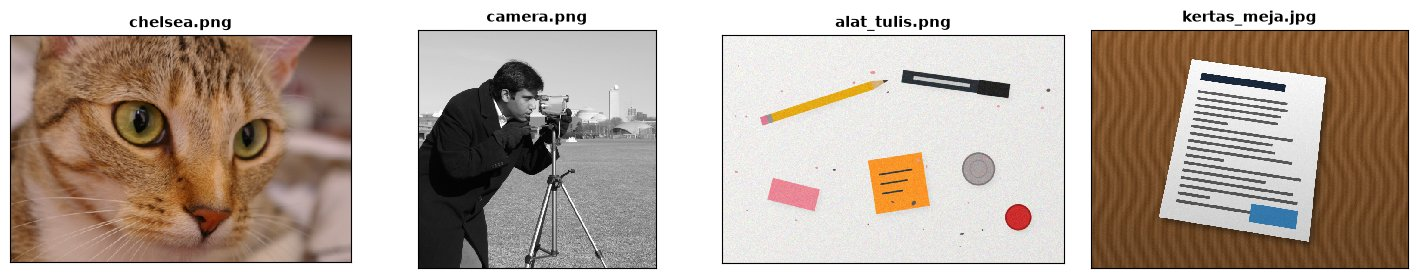

In [2]:
# Pencarian berkas citra defensif (notebook bisa dijalankan dari root repo atau folder notebook_handson)
def find_image(filename):
    possible_paths = [
        f"image/{filename}",
        f"notebook_handson/image/{filename}",
        f"../image/{filename}",
    ]
    return next((p for p in possible_paths if os.path.exists(p)), None)


def baca(filename, flag=cv2.IMREAD_COLOR):
    # cv2.imread TIDAK melempar error bila path salah -> kita periksa sendiri
    path = find_image(filename)
    img = cv2.imread(path, flag) if path else None
    if img is None:
        raise FileNotFoundError(f"Citra tidak ditemukan / gagal dibaca: {filename}")
    return img


def tampil(ax, img, judul=None):
    # Menampilkan citra OpenCV (BGR / grayscale) di matplotlib
    if img.ndim == 2:
        ax.imshow(img, cmap='gray', vmin=0, vmax=255, interpolation='nearest')
    else:
        ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB), interpolation='nearest')
    ax.set_xticks([]); ax.set_yticks([])
    if judul:
        ax.set_title(judul, fontsize=11, fontweight='bold')


def jajar(daftar, ukuran=4):
    # Menampilkan beberapa citra berdampingan: daftar = [(img, judul), ...]
    fig, axes = plt.subplots(1, len(daftar), figsize=(ukuran * len(daftar), ukuran * 0.8))
    for ax, (im, judul) in zip(np.atleast_1d(axes), daftar):
        tampil(ax, im, judul)
    plt.tight_layout(); plt.show()


def ke_uint8(a):
    # Hasil filter tepi bisa negatif / > 255 -> ambil nilai mutlak lalu skala ke 0..255 agar bisa ditampilkan
    a = np.abs(a)
    return np.clip(a / (a.max() + 1e-9) * 255, 0, 255).astype(np.uint8)


def perbesar(img, s):
    # Perbesar tanpa menghaluskan, supaya kotak-kotak piksel terlihat
    return cv2.resize(img, None, fx=s, fy=s, interpolation=cv2.INTER_NEAREST)


kucing = baca("chelsea.png")
kamera = baca("camera.png", cv2.IMREAD_GRAYSCALE)
alat = baca("alat_tulis.png")
meja = baca("kertas_meja.jpg")

print("kucing:", kucing.shape, "| kamera:", kamera.shape, "| alat:", alat.shape, "| meja:", meja.shape)
jajar([(kucing, "chelsea.png"), (kamera, "camera.png"), (alat, "alat_tulis.png"), (meja, "kertas_meja.jpg")], ukuran=3.6)

---
## 2. Konvolusi: Piksel Menengok Tetangganya

Di Pertemuan 6 kita mengubah **nilai** piksel sendiri-sendiri. Di Pertemuan 7 kita memindahkan **alamat** piksel.
Hari ini, nilai baru setiap piksel dihitung dari **dirinya dan tetangganya**.

**Kernel** adalah "resep campuran" kecil, misalnya 3×3. Caranya:
1. Letakkan kernel di atas sebuah piksel beserta 8 tetangganya.
2. Kalikan setiap angka citra dengan angka kernel di atasnya.
3. Jumlahkan → itulah nilai baru piksel tengah.
4. Geser kernel satu piksel, ulangi untuk semua piksel.

### 2.1 Hitung dengan Tangan, Lalu dengan Komputer
Grid 5×5 berikut semuanya bernilai 50, kecuali satu titik noise bernilai 230 di tengah (sama dengan aktivitas di slide).

In [3]:
def konvolusi_manual(img, kernel):
    # Konvolusi 'apa adanya': geser jendela, kalikan, jumlahkan (pinggiran = salin piksel tepi)
    k = kernel.shape[0] // 2
    pad = np.pad(img.astype(np.float64), k, mode="edge")
    out = np.zeros(img.shape, np.float64)
    for y in range(img.shape[0]):
        for x in range(img.shape[1]):
            jendela = pad[y:y + 2 * k + 1, x:x + 2 * k + 1]   # 3x3 tetangga di sekitar (x, y)
            out[y, x] = (jendela * kernel).sum()              # kalikan lalu jumlahkan
    return out


grid = np.full((5, 5), 50.0)
grid[2, 2] = 230                       # satu titik noise

box3 = np.ones((3, 3)) / 9             # rata-rata biasa: semua tetangga sama penting
gauss3 = np.array([[1, 2, 1],
                   [2, 4, 2],
                   [1, 2, 1]]) / 16    # Gaussian kecil: tetangga dekat lebih penting
tajam3 = np.array([[0, -1, 0],
                   [-1, 5, -1],
                   [0, -1, 0]], float) # sharpening: diri sendiri diperkuat, tetangga dikurangi

print("Grid asli:\n", grid.astype(int))
print("\nPiksel tengah setelah rata-rata (box) :", round(konvolusi_manual(grid, box3)[2, 2], 1))
print("Piksel tengah setelah Gaussian 3x3     :", round(konvolusi_manual(grid, gauss3)[2, 2], 1))
print("Piksel tengah setelah median 3x3       :", np.median(grid[1:4, 1:4]))
print("Piksel tengah setelah sharpening       :", round(konvolusi_manual(grid, tajam3)[2, 2], 1), "-> dipotong jadi 255")

Grid asli:
 [[ 50  50  50  50  50]
 [ 50  50  50  50  50]
 [ 50  50 230  50  50]
 [ 50  50  50  50  50]
 [ 50  50  50  50  50]]

Piksel tengah setelah rata-rata (box) : 70.0
Piksel tengah setelah Gaussian 3x3     : 95.0
Piksel tengah setelah median 3x3       : 50.0
Piksel tengah setelah sharpening       : 950.0 -> dipotong jadi 255


**Perhatikan:** rata-rata hanya *mengencerkan* noise (230 → 70), Gaussian lebih sedikit lagi (230 → 95), median *menghapusnya* (→ 50),
dan sharpening malah *memperparah* (→ 950, lalu dipotong ke 255). Kita akan bertemu lagi dengan keempat angka ini.

### 2.2 OpenCV Melakukan Hal yang Sama, Jauh Lebih Cepat
`cv2.filter2D(img, -1, kernel)` menjalankan konvolusi untuk seluruh citra. Hasilnya identik dengan fungsi manual kita.

In [4]:
potong = kamera[:60, :60]
hasil_manual = konvolusi_manual(potong, box3)
hasil_cv = cv2.filter2D(potong.astype(np.float64), -1, box3, borderType=cv2.BORDER_REPLICATE)
print("Selisih terbesar manual vs filter2D:", np.abs(hasil_manual - hasil_cv).max())

import time
t0 = time.perf_counter(); konvolusi_manual(kamera, box3); t1 = time.perf_counter()
cv2.filter2D(kamera, -1, box3); t2 = time.perf_counter()
print(f"Seluruh citra 512x512 -> manual: {t1 - t0:.2f} s | filter2D: {(t2 - t1) * 1000:.2f} ms")

Selisih terbesar manual vs filter2D: 5.684341886080802e-14


Seluruh citra 512x512 -> manual: 0.46 s | filter2D: 0.33 ms


### 2.3 🎬 Demo Dosen — Tebak Kernel
Empat kernel 3×3 diterapkan pada wajah kucing yang diperkecil. Sebelum menjalankan sel, tebak: kernel mana yang membuat citra **buram**, **tajam**, **hanya garis tepi**, dan **tidak berubah sama sekali**?

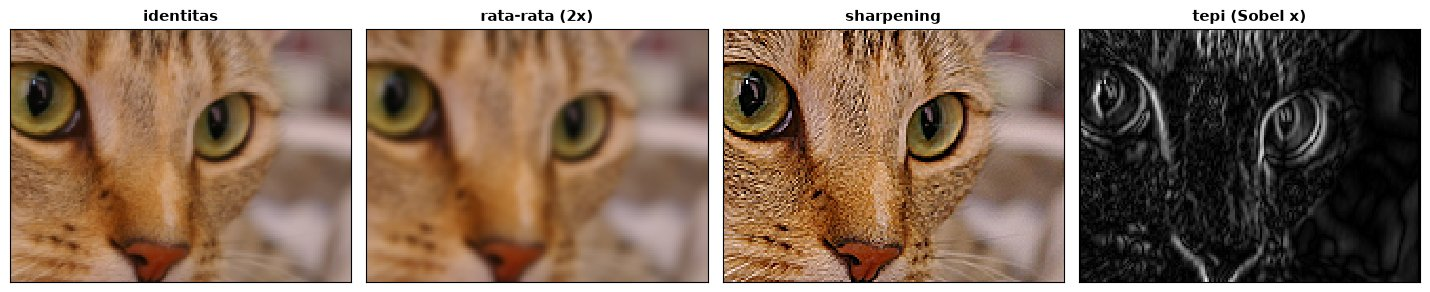

In [5]:
wajah = cv2.resize(kucing[60:260, 150:420], (162, 120), interpolation=cv2.INTER_AREA)
identitas = np.array([[0, 0, 0], [0, 1, 0], [0, 0, 0]], float)
sobel_x = np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]], float)

kernel_uji = {
    "identitas": cv2.filter2D(wajah, -1, identitas),
    "rata-rata (2x)": cv2.filter2D(cv2.filter2D(wajah, -1, box3), -1, box3),
    "sharpening": cv2.filter2D(wajah, -1, tajam3),
    "tepi (Sobel x)": ke_uint8(cv2.filter2D(cv2.cvtColor(wajah, cv2.COLOR_BGR2GRAY).astype(np.float64), -1, sobel_x)),
}
jajar([(perbesar(im, 3), nama) for nama, im in kernel_uji.items()], ukuran=3.6)

### 2.4 Bagaimana dengan Piksel di Pinggir?
Piksel di pinggir tidak punya tetangga lengkap. OpenCV "menambal" bingkai di luar citra (*padding*) dengan salah satu cara berikut.
Default `cv2.filter2D` dan `cv2.GaussianBlur` adalah **cermin** (`BORDER_REFLECT_101`).

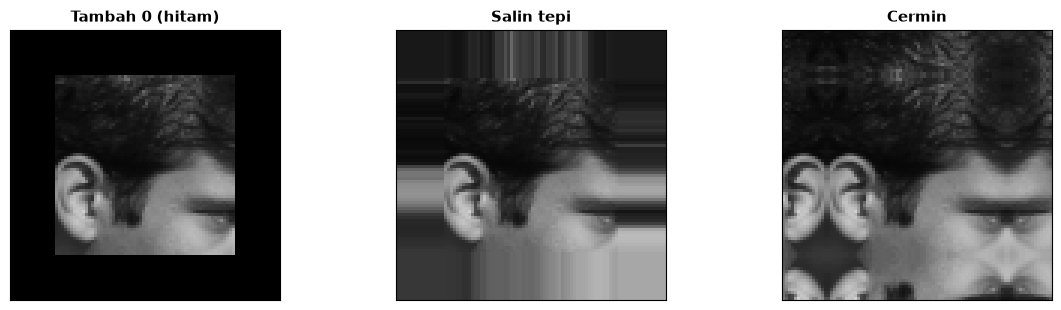

In [6]:
mini = kamera[100:160, 180:240]
cara = [("Tambah 0 (hitam)", cv2.BORDER_CONSTANT), ("Salin tepi", cv2.BORDER_REPLICATE), ("Cermin", cv2.BORDER_REFLECT)]
jajar([(perbesar(cv2.copyMakeBorder(mini, 15, 15, 15, 15, b, value=0), 4), t) for t, b in cara], ukuran=4)

---
## 3. Blur: Mengusir Noise

### 3.1 Box Blur (Rata-rata)
`cv2.blur(img, (k, k))` mengambil rata-rata k×k tetangga. Makin besar k, makin buram.

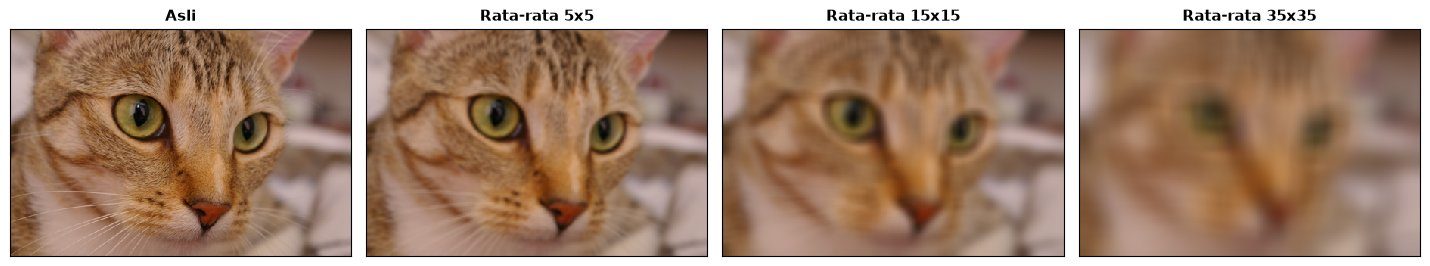

In [7]:
jajar([(kucing, "Asli")] + [(cv2.blur(kucing, (k, k)), f"Rata-rata {k}x{k}") for k in (5, 15, 35)], ukuran=3.6)

### 3.2 Gaussian Blur: Rata-rata yang Lebih Sayang Tetangga Dekat
Pada Gaussian, tetangga yang **dekat** mendapat bobot **besar**, yang jauh hampir nol. Besarnya "jangkauan" diatur oleh **σ (sigma)**.

In [8]:
g1 = cv2.getGaussianKernel(5, 1.0)      # kernel 1D
G = g1 @ g1.T                            # kernel 2D 5x5
print("Bobot box 5x5 (persen):\n", np.round(np.full((5, 5), 100 / 25), 1))
print("\nBobot Gaussian 5x5, sigma = 1 (persen):\n", np.round(G * 100, 1))
print("\nTotal bobot Gaussian:", round(G.sum(), 4), "(selalu 1 -> kecerahan rata-rata tidak berubah)")

Bobot box 5x5 (persen):
 [[4. 4. 4. 4. 4.]
 [4. 4. 4. 4. 4.]
 [4. 4. 4. 4. 4.]
 [4. 4. 4. 4. 4.]
 [4. 4. 4. 4. 4.]]

Bobot Gaussian 5x5, sigma = 1 (persen):
 [[ 0.3  1.3  2.2  1.3  0.3]
 [ 1.3  6.   9.8  6.   1.3]
 [ 2.2  9.8 16.2  9.8  2.2]
 [ 1.3  6.   9.8  6.   1.3]
 [ 0.3  1.3  2.2  1.3  0.3]]

Total bobot Gaussian: 1.0 (selalu 1 -> kecerahan rata-rata tidak berubah)


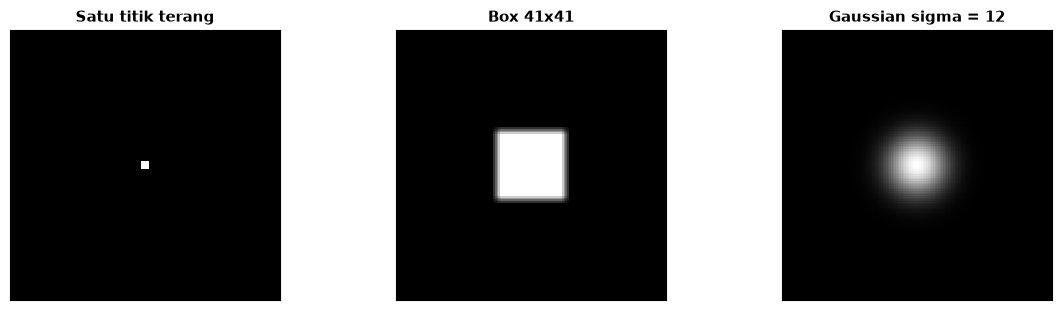

In [9]:
# Uji satu titik terang: box membuatnya KOTAK, Gaussian membuatnya BULAT
titik = np.zeros((161, 161), np.uint8)
titik[78:83, 78:83] = 255
box_titik = cv2.blur(titik.astype(np.float32), (41, 41))
gauss_titik = cv2.GaussianBlur(titik.astype(np.float32), (0, 0), 12)
jajar([(titik, "Satu titik terang"), (ke_uint8(box_titik), "Box 41x41"), (ke_uint8(gauss_titik), "Gaussian sigma = 12")])

### 3.3 Dua Jenis Noise
- **Noise Gaussian**: setiap piksel bergeser sedikit secara acak (seperti foto kamera HP di ruangan gelap).
- **Noise salt & pepper**: sebagian kecil piksel tiba-tiba hitam pekat atau putih pekat (seperti piksel mati / gangguan transmisi).

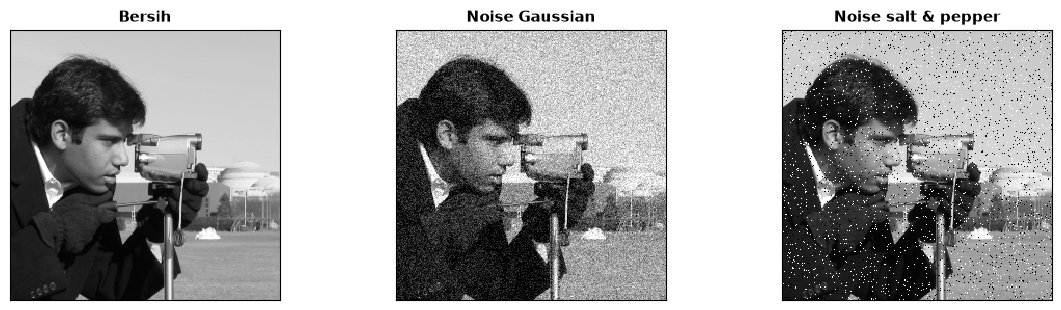

In [10]:
def tambah_noise_gauss(img, sigma, seed=0):
    rng = np.random.default_rng(seed)
    return np.clip(img + rng.normal(0, sigma, img.shape), 0, 255).astype(np.uint8)


def tambah_salt_pepper(img, persen, seed=0):
    rng = np.random.default_rng(seed)
    out = img.copy()
    acak = rng.random(img.shape[:2])
    out[acak < persen / 2] = 0          # pepper (hitam)
    out[acak > 1 - persen / 2] = 255    # salt (putih)
    return out


bersih = kamera[40:300, 140:400]
noise_g = tambah_noise_gauss(bersih, 25)
noise_sp = tambah_salt_pepper(bersih, 0.06)
jajar([(bersih, "Bersih"), (noise_g, "Noise Gaussian"), (noise_sp, "Noise salt & pepper")])

### 3.4 🎬 Demo Dosen — Studi Kasus: Asli vs Gaussian Blur
Kita ukur kualitas dengan **PSNR** (makin besar makin mirip citra bersih; ingat Modul 07).
Tebak dulu: apakah σ yang **makin besar** selalu **makin baik**?

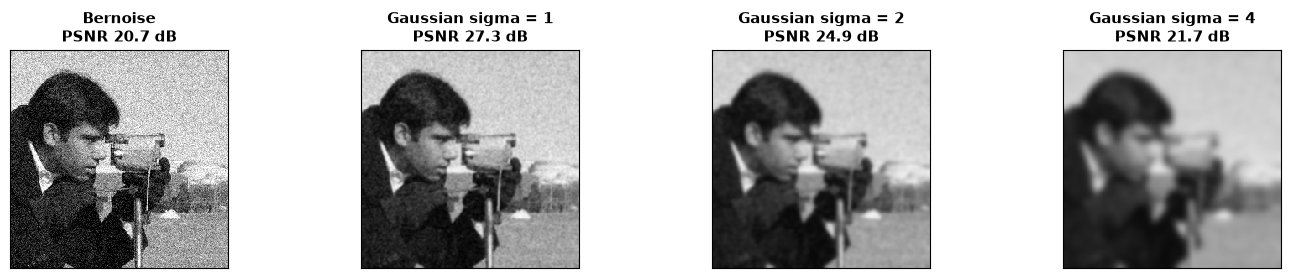

In [11]:
# ✏️ Coba Ubah: daftar sigma yang dicoba
DAFTAR_SIGMA = [1, 2, 4]

hasil = [(noise_g, f"Bernoise\nPSNR {cv2.PSNR(bersih, noise_g):.1f} dB")]
for s in DAFTAR_SIGMA:
    r = cv2.GaussianBlur(noise_g, (0, 0), s)       # (0, 0) = ukuran kernel dihitung otomatis dari sigma
    hasil.append((r, f"Gaussian sigma = {s}\nPSNR {cv2.PSNR(bersih, r):.1f} dB"))
jajar(hasil, ukuran=3.6)

**Pelajaran:** blur sedikit (σ = 1) menaikkan PSNR, tetapi blur berlebihan ikut menghapus **detail asli**, sehingga PSNR turun lagi.
Blur selalu merupakan **tawar-menawar** antara "bersih" dan "tajam".

### 3.5 Median Filter: Ambil Nilai Tengah
Median **mengurutkan** 9 nilai tetangga lalu mengambil yang **di tengah**. Titik ekstrem (0 atau 255) tidak pernah menjadi nilai tengah, sehingga **hilang total** tanpa mengencerkan tetangganya.

9 tetangga di sekitar titik noise: [50, 50, 50, 50, 50, 50, 50, 50, 230] -> median = 50.0


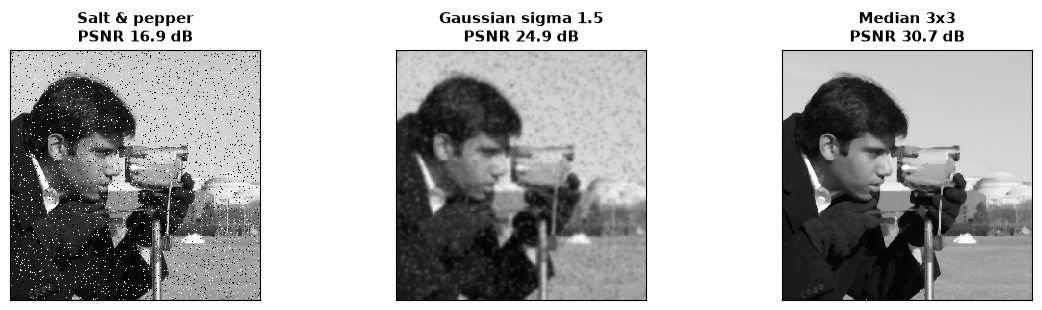

In [12]:
print("9 tetangga di sekitar titik noise:", sorted(grid[1:4, 1:4].ravel().astype(int).tolist()), "-> median =", np.median(grid[1:4, 1:4]))

gauss_sp = cv2.GaussianBlur(noise_sp, (0, 0), 1.5)
median_sp = cv2.medianBlur(noise_sp, 3)              # ukuran harus ganjil: 3, 5, 7, ...
jajar([(noise_sp, f"Salt & pepper\nPSNR {cv2.PSNR(bersih, noise_sp):.1f} dB"),
       (gauss_sp, f"Gaussian sigma 1.5\nPSNR {cv2.PSNR(bersih, gauss_sp):.1f} dB"),
       (median_sp, f"Median 3x3\nPSNR {cv2.PSNR(bersih, median_sp):.1f} dB")])

| Jenis noise | Filter yang cocok |
|---|---|
| Gaussian (bintik halus merata) | `cv2.GaussianBlur` (σ kecil) |
| Salt & pepper (titik ekstrem) | `cv2.medianBlur` |
| Ingin efek buram artistik | `cv2.GaussianBlur` (σ besar) |

---
## 4. Sharpening: Mempertajam dengan Unsharp Mask

Ide paling sederhana:
1. **Blur** citra → yang tersisa hanya bagian "halus".
2. **Detail** = asli − blur → yang tersisa hanya bagian "tajam" (tepi & tekstur).
3. **Tajam** = asli + k × detail.

Nama "unsharp mask" berasal dari kamar gelap fotografi: salinan film yang *dibuat buram* dipakai untuk mempertajam cetakan.

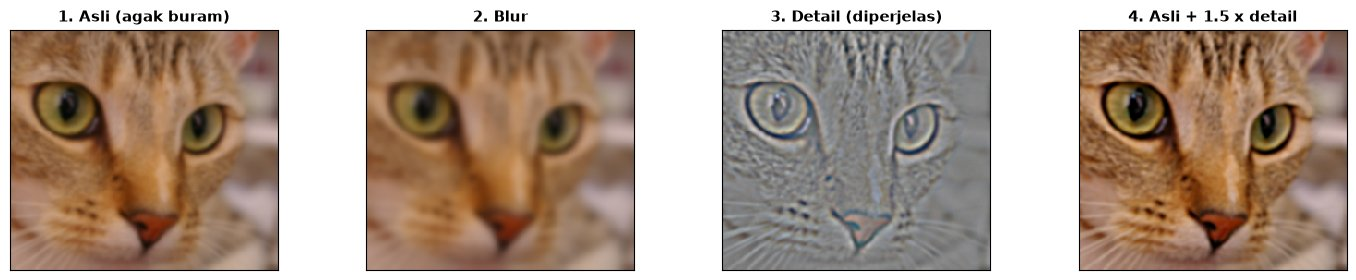

In [13]:
def tajamkan(img, sigma=2, k=1.0):
    # Unsharp mask: tajam = asli + k * (asli - blur) = (1 + k) * asli - k * blur
    blur = cv2.GaussianBlur(img, (0, 0), sigma)
    return cv2.addWeighted(img, 1 + k, blur, -k, 0)


lembut = cv2.GaussianBlur(kucing[30:290, 110:400], (0, 0), 1.6)    # anggap ini foto yang agak buram
blur = cv2.GaussianBlur(lembut, (0, 0), 3)
detail = np.clip((lembut.astype(np.int16) - blur) * 3 + 128, 0, 255).astype(np.uint8)   # x3 + 128 agar terlihat
jajar([(lembut, "1. Asli (agak buram)"), (blur, "2. Blur"), (detail, "3. Detail (diperjelas)"),
       (tajamkan(lembut, 3, 1.5), "4. Asli + 1.5 x detail")], ukuran=3.6)

### 4.1 Hati-hati Sharpening Berlebihan
Sharpening juga memperkuat **noise** dan menimbulkan **halo** (garis terang/gelap palsu di sekitar tepi).

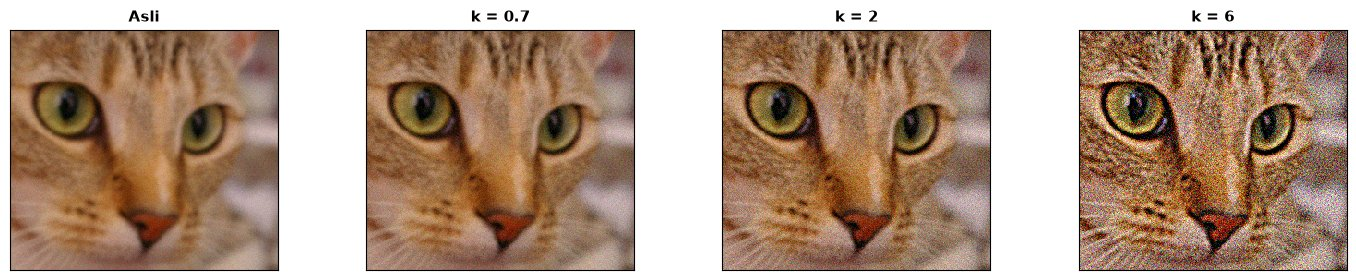

In [14]:
# ✏️ Coba Ubah: kekuatan sharpening
DAFTAR_K = [0.7, 2, 6]

sedikit_noise = tambah_noise_gauss(lembut, 6, seed=3)
jajar([(sedikit_noise, "Asli")] + [(tajamkan(sedikit_noise, 2, k), f"k = {k}") for k in DAFTAR_K], ukuran=3.6)

### 4.2 Versi Kernel 3×3
Kernel `[[0,-1,0],[-1,5,-1],[0,-1,0]]` adalah unsharp mask versi kecil: "diri sendiri ×5, kurangi 4 tetangga".

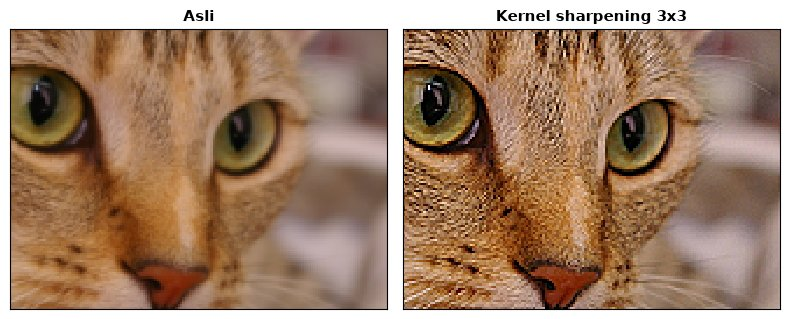

In [15]:
jajar([(wajah, "Asli"), (cv2.filter2D(wajah, -1, tajam3), "Kernel sharpening 3x3")], ukuran=4)

---
## 5. Deteksi Tepi

**Tepi** adalah tempat kecerahan **berubah mendadak**. Cara paling sederhana menemukannya: bandingkan **tetangga kanan** dengan **tetangga kiri**.
Kalau selisihnya besar, di situ ada tepi.

### 5.1 Profil Satu Baris

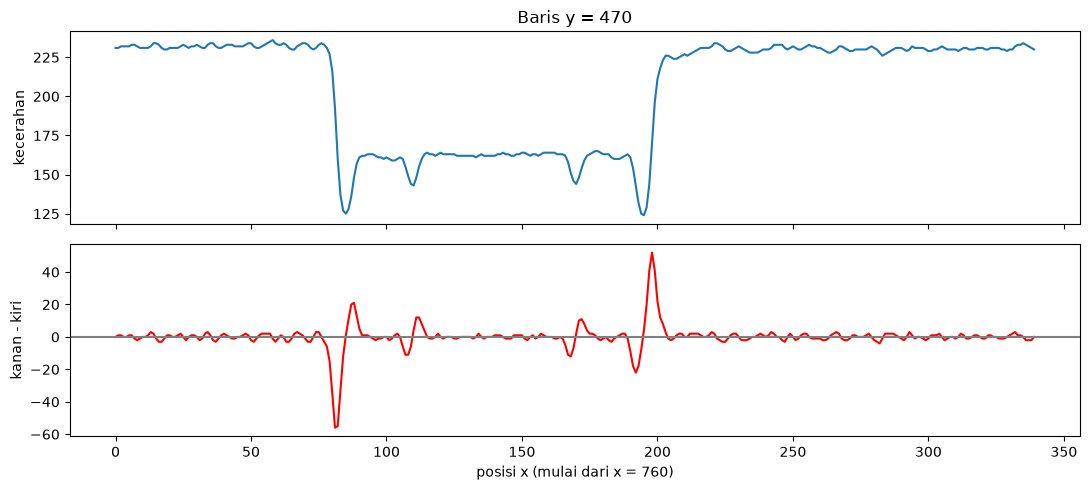

In [16]:
abu_alat = cv2.cvtColor(alat, cv2.COLOR_BGR2GRAY)
BARIS = 470                                           # baris yang melewati koin
profil = cv2.GaussianBlur(abu_alat, (5, 5), 0)[BARIS, 760:1100].astype(float)
selisih = np.zeros_like(profil)
selisih[1:-1] = profil[2:] - profil[:-2]              # kanan - kiri

fig, axes = plt.subplots(2, 1, figsize=(11, 5), sharex=True)
axes[0].plot(profil); axes[0].set_ylabel("kecerahan"); axes[0].set_title(f"Baris y = {BARIS}")
axes[1].plot(selisih, color="red"); axes[1].axhline(0, color="gray"); axes[1].set_ylabel("kanan - kiri")
axes[1].set_xlabel("posisi x (mulai dari x = 760)")
plt.tight_layout(); plt.show()

### 5.2 Sobel: Tepi Tegak, Tepi Mendatar, dan Gabungannya
- **Sobel x** membandingkan kanan vs kiri → menemukan tepi **tegak**.
- **Sobel y** membandingkan bawah vs atas → menemukan tepi **mendatar**.
- **Gabungan** (`np.hypot(gx, gy)`) = kekuatan tepi ke segala arah.

Hasil Sobel bisa **negatif**, jadi hitung dengan `cv2.CV_64F` (bukan `uint8`) agar tidak terpotong.

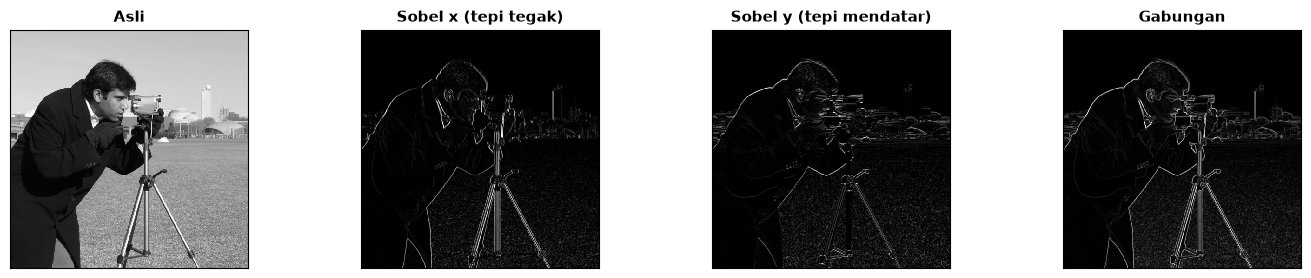

In [17]:
def sobel_mag(abu):
    gx = cv2.Sobel(abu, cv2.CV_64F, 1, 0, ksize=3)
    gy = cv2.Sobel(abu, cv2.CV_64F, 0, 1, ksize=3)
    return gx, gy, np.hypot(gx, gy)


gx, gy, mag = sobel_mag(kamera)
jajar([(kamera, "Asli"), (ke_uint8(gx), "Sobel x (tepi tegak)"), (ke_uint8(gy), "Sobel y (tepi mendatar)"),
       (ke_uint8(mag), "Gabungan")], ukuran=3.6)

### 5.3 Noise Juga Terlihat Seperti Tepi → Blur Dulu

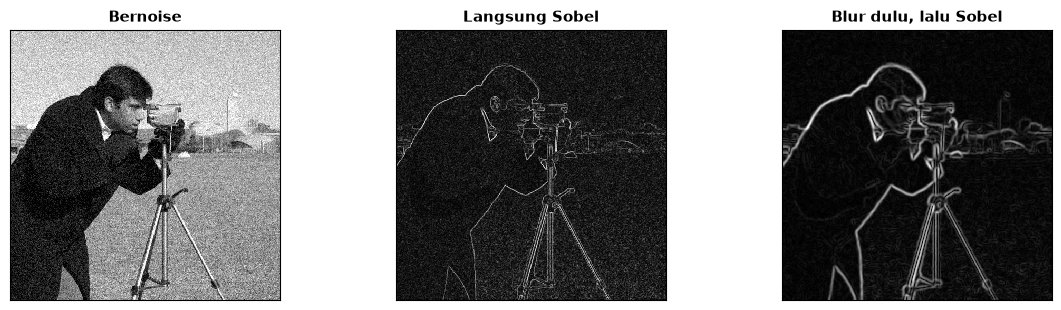

In [18]:
kamera_noise = tambah_noise_gauss(kamera, 20, seed=5)
_, _, mag_noise = sobel_mag(kamera_noise)
_, _, mag_blur = sobel_mag(cv2.GaussianBlur(kamera_noise, (0, 0), 2))
jajar([(kamera_noise, "Bernoise"), (ke_uint8(mag_noise), "Langsung Sobel"), (ke_uint8(mag_blur), "Blur dulu, lalu Sobel")])

### 5.4 Canny: Detektor Tepi Paling Populer
`cv2.Canny(img, ambang_bawah, ambang_atas)` menjalankan 4 langkah sekaligus:
1. **Blur** untuk meredam noise.
2. **Gradien** (seperti Sobel) → tepi masih tebal.
3. **Penipisan** → hanya puncak tepi yang disimpan, tebal 1 piksel.
4. **Dua ambang**: piksel di atas `ambang_atas` = tepi **kuat** (pasti disimpan). Piksel di antara dua ambang = tepi **lemah**, disimpan **hanya jika tersambung** ke tepi kuat. Di bawah `ambang_bawah` dibuang.

Aturan praktis: `ambang_atas` ≈ 2–3 × `ambang_bawah`.

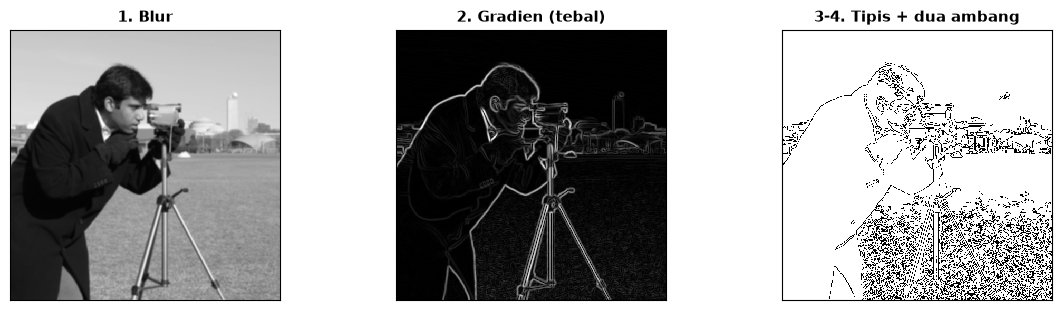

In [19]:
kamera_blur = cv2.GaussianBlur(kamera, (5, 5), 1.4)
_, _, mag_kb = sobel_mag(kamera_blur)
tepi = cv2.Canny(kamera, 50, 150)
jajar([(kamera_blur, "1. Blur"), (ke_uint8(mag_kb), "2. Gradien (tebal)"), (255 - tepi, "3-4. Tipis + dua ambang")])

### 5.5 🎬 Demo Dosen — Memilih Dua Ambang Canny
Tebak dulu: pasangan ambang mana yang menghasilkan garis paling "bersih" — `(10, 30)`, `(50, 150)`, atau `(150, 300)`?

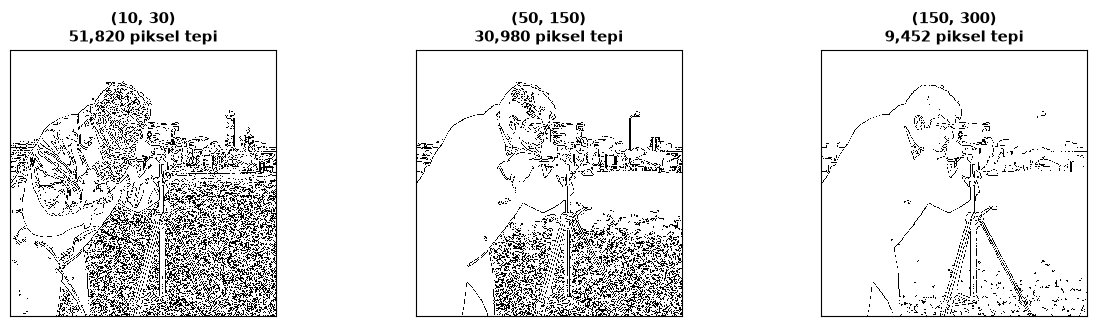

In [20]:
# ✏️ Coba Ubah: pasangan (ambang_bawah, ambang_atas)
DAFTAR_AMBANG = [(10, 30), (50, 150), (150, 300)]

hasil = []
for lo, hi in DAFTAR_AMBANG:
    e = cv2.Canny(kamera, lo, hi)
    hasil.append((255 - e, f"({lo}, {hi})\n{int((e > 0).sum()):,} piksel tepi"))
jajar(hasil, ukuran=4.2)

---
## 6. Dari Foto ke Mask: Threshold & Morfologi

Studi kasus kita: **foto alat tulis di atas kertas**. Tujuannya menghitung, menandai, dan mengenali setiap objek.

### 6.1 Threshold Otsu
Objek lebih **gelap** daripada kertas. Kita ubah citra menjadi hitam-putih (**mask**): objek = putih (255), latar = hitam (0).
Metode **Otsu** memilih ambang secara otomatis dari histogram (mencari "lembah" di antara dua kelompok kecerahan).
`THRESH_BINARY_INV` dipakai karena objeknya **lebih gelap** dari latar.

Ambang Otsu = 186.0


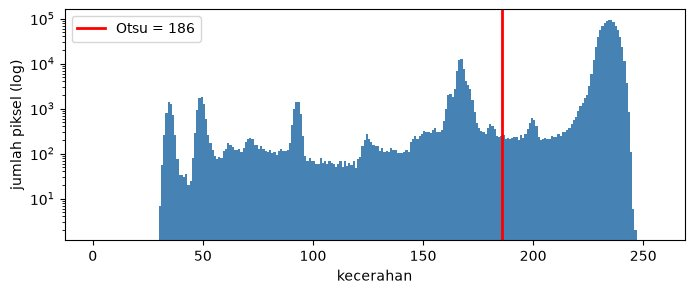

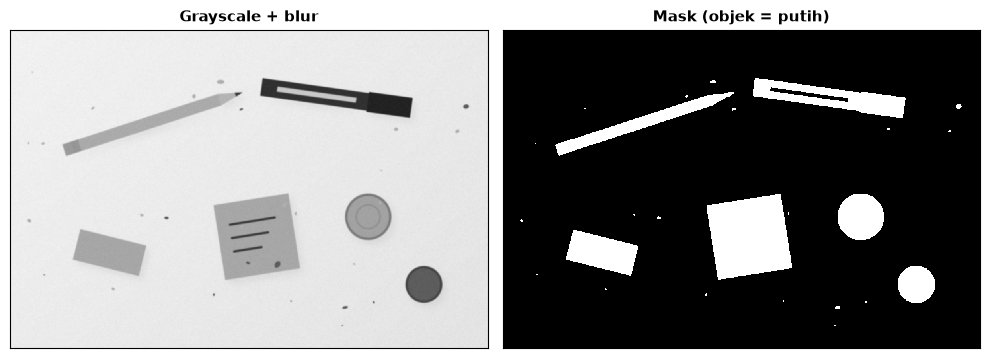

In [21]:
abu = cv2.cvtColor(alat, cv2.COLOR_BGR2GRAY)
halus = cv2.GaussianBlur(abu, (5, 5), 0)             # blur dulu agar noise kamera tidak ikut
T, mask = cv2.threshold(halus, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
print("Ambang Otsu =", T)

fig, ax = plt.subplots(figsize=(8, 3))
ax.hist(halus.ravel(), bins=256, range=(0, 256), log=True, color="steelblue")
ax.axvline(T, color="red", lw=2, label=f"Otsu = {T:.0f}"); ax.legend()
ax.set_xlabel("kecerahan"); ax.set_ylabel("jumlah piksel (log)")
plt.show()
jajar([(halus, "Grayscale + blur"), (mask, "Mask (objek = putih)")], ukuran=5)

### 6.2 Morfologi: Merapikan Mask
Mask masih memuat **remah penghapus** (bintik kecil) dan **lubang** (garis putih pada spidol). Morfologi memakai "kuas" kecil (*structuring element*):

| Operasi | Analogi | Efek |
|---|---|---|
| **Erosi** | amplas | objek mengecil, bintik kecil hilang |
| **Dilasi** | spidol tebal | objek membesar, lubang kecil tertutup |
| **Opening** = erosi → dilasi | "hapus remah" | bintik hilang, ukuran objek kembali |
| **Closing** = dilasi → erosi | "tambal lubang" | lubang tertutup, ukuran objek kembali |

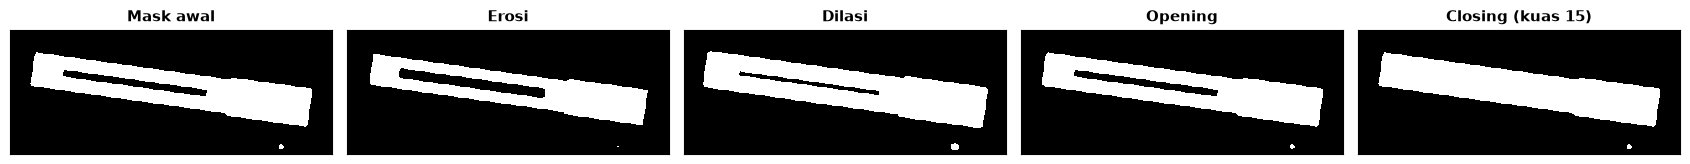

In [22]:
potongan = mask[90:260, 600:1040]
kuas = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))
kuas_besar = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (15, 15))
jajar([(potongan, "Mask awal"),
       (cv2.erode(potongan, kuas), "Erosi"),
       (cv2.dilate(potongan, kuas), "Dilasi"),
       (cv2.morphologyEx(potongan, cv2.MORPH_OPEN, kuas), "Opening"),
       (cv2.morphologyEx(potongan, cv2.MORPH_CLOSE, kuas_besar), "Closing (kuas 15)")], ukuran=3.4)

Efeknya lebih mudah dilihat pada **mask mainan** berikut: ada bintik kecil, lubang kecil, dan jembatan tipis (sama dengan slide).

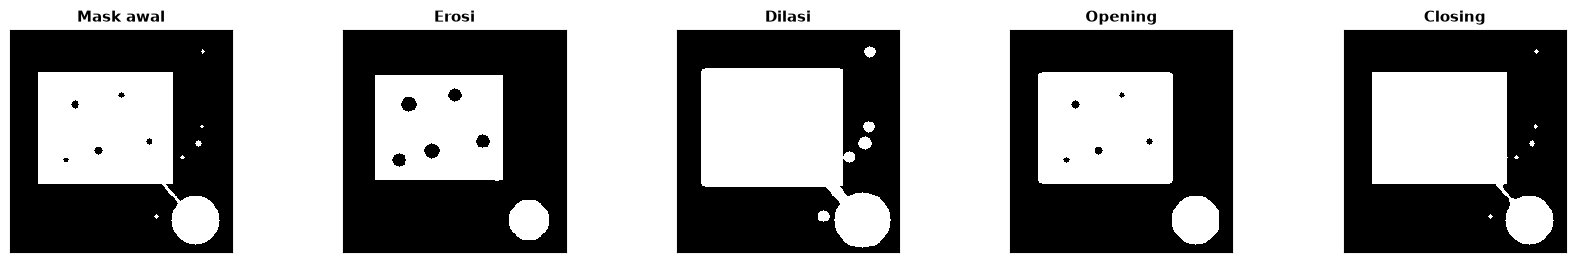

In [23]:
toy = np.zeros((240, 240), np.uint8)
cv2.rectangle(toy, (30, 45), (175, 165), 255, -1)
for cx_, cy_, r_ in [(70, 80, 4), (120, 70, 3), (95, 130, 4), (150, 120, 3), (60, 140, 3)]:
    cv2.circle(toy, (cx_, cy_), r_, 0, -1)                       # lubang kecil
cv2.circle(toy, (200, 205), 26, 255, -1)
cv2.line(toy, (160, 160), (195, 200), 255, 2)                    # jembatan tipis
rt = np.random.default_rng(4)
for _ in range(12):
    x_, y_ = int(rt.integers(10, 230)), int(rt.integers(10, 230))
    if toy[max(y_ - 8, 0):y_ + 8, max(x_ - 8, 0):x_ + 8].max() == 0:
        cv2.circle(toy, (x_, y_), int(rt.integers(2, 4)), 255, -1)   # bintik

# ✏️ Coba Ubah: ukuran kuas (ganjil). Makin besar, makin kuat efeknya.
UKURAN_KUAS = 9
kuas_toy = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (UKURAN_KUAS, UKURAN_KUAS))
jajar([(toy, "Mask awal"),
       (cv2.erode(toy, kuas_toy), "Erosi"),
       (cv2.dilate(toy, kuas_toy), "Dilasi"),
       (cv2.morphologyEx(toy, cv2.MORPH_OPEN, kuas_toy), "Opening"),
       (cv2.morphologyEx(toy, cv2.MORPH_CLOSE, kuas_toy), "Closing")], ukuran=3.4)

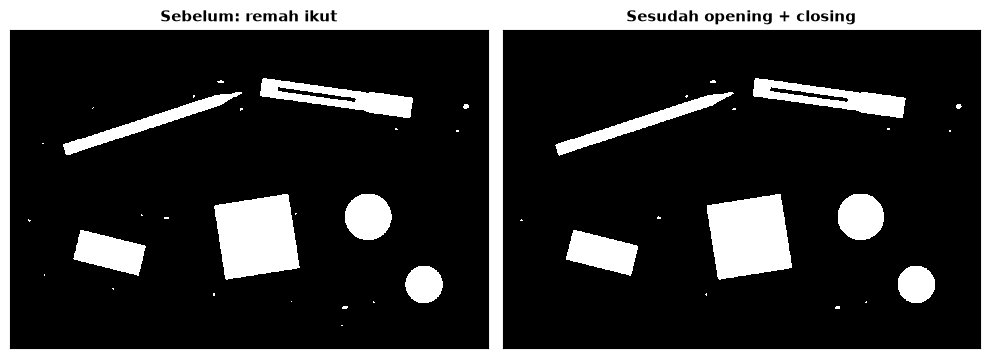

In [24]:
def buat_mask(img, k_morf=5):
    # Pipeline lengkap: grayscale -> blur -> Otsu -> opening -> closing
    abu = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    halus = cv2.GaussianBlur(abu, (5, 5), 0)
    T, mask = cv2.threshold(halus, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
    kuas = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (k_morf, k_morf))
    bersih = cv2.morphologyEx(mask, cv2.MORPH_OPEN, kuas)
    bersih = cv2.morphologyEx(bersih, cv2.MORPH_CLOSE, kuas)
    return halus, T, mask, bersih


halus, T, mask, mask_bersih = buat_mask(alat)
jajar([(mask, "Sebelum: remah ikut"), (mask_bersih, "Sesudah opening + closing")], ukuran=5)

---
## 7. Kontur: Garis Keliling Objek

**Kontur** adalah daftar titik yang mengelilingi satu objek putih pada mask.
- `cv2.RETR_EXTERNAL` → hanya kontur terluar (lubang di dalam objek diabaikan).
- `cv2.CHAIN_APPROX_SIMPLE` → titik pada garis lurus mendatar/tegak dibuang agar hemat memori.

### 7.1 🎬 Demo Dosen — Berapa Objek yang Ditemukan?
Tebak dulu: kalau kita mencari kontur langsung pada mask awal (sebelum dirapikan), berapa "objek" yang ditemukan? Kenyataannya hanya ada 6 alat tulis.

Kontur pada mask awal      : 25
Kontur setelah morfologi   : 17


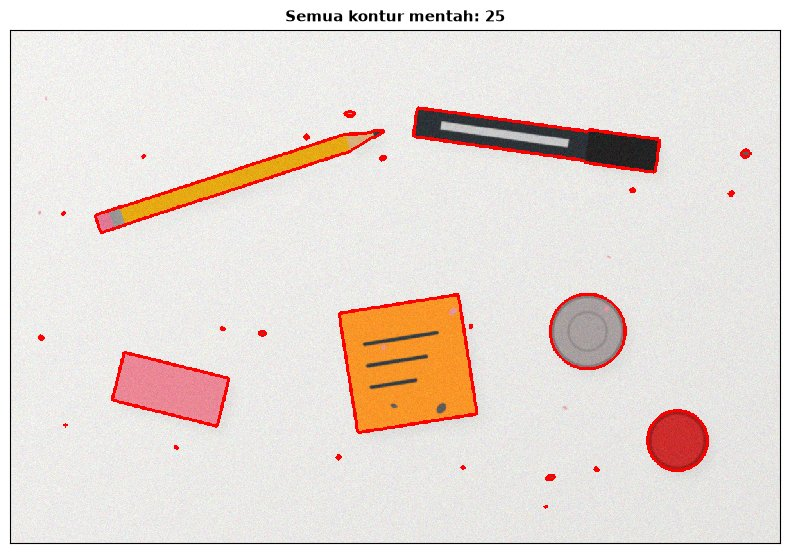

In [25]:
kontur_mentah, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
kontur_bersih, _ = cv2.findContours(mask_bersih, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
print("Kontur pada mask awal      :", len(kontur_mentah))
print("Kontur setelah morfologi   :", len(kontur_bersih))

gambar = alat.copy()                                  # selalu menggambar di SALINAN (ingat Modul 08)
cv2.drawContours(gambar, kontur_mentah, -1, (0, 0, 255), 3)   # -1 = gambar semua kontur
jajar([(gambar, f"Semua kontur mentah: {len(kontur_mentah)}")], ukuran=8)

### 7.2 Saring Berdasarkan Luas
Remah yang masih tersisa punya luas sangat kecil. Kita buang semua kontur yang luasnya di bawah batas.

In [26]:
# ✏️ Coba Ubah: batas luas minimum (piksel)
MIN_LUAS = 500

luas = sorted(int(cv2.contourArea(c)) for c in kontur_bersih)
print("Luas semua kontur (urut):", luas)

objek = [c for c in kontur_bersih if cv2.contourArea(c) >= MIN_LUAS]
objek = sorted(objek, key=lambda c: cv2.boundingRect(c)[0])     # urutkan dari kiri ke kanan
print(f"Objek dengan luas >= {MIN_LUAS}: {len(objek)}")

Luas semua kontur (urut): [10, 14, 21, 21, 21, 22, 31, 50, 71, 81, 118, 6882, 10654, 12255, 12942, 18057, 35460]
Objek dengan luas >= 500: 6


### 7.3 Gambar Ulang dengan Warna Berbeda

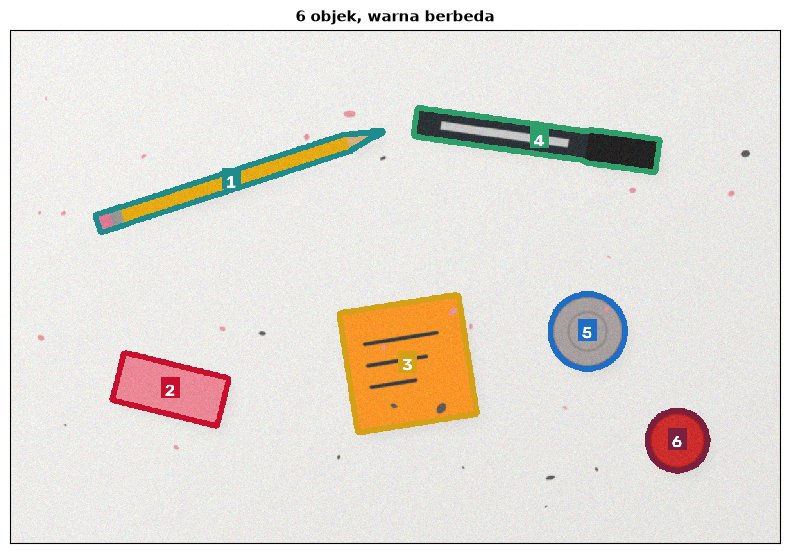

In [27]:
WARNA = [(140, 140, 30), (46, 16, 200), (23, 160, 212), (107, 158, 46), (200, 110, 30), (61, 31, 122),
         (57, 123, 224), (58, 31, 11)]   # BGR: teal, merah, emas, hijau, biru, burgundy, oranye, navy


def label(img, xy, teks, warna, skala=0.7):
    # Teks berlatar warna, berpusat di xy (pola draw_label Modul 08)
    (tw, th), b = cv2.getTextSize(teks, cv2.FONT_HERSHEY_SIMPLEX, skala, 2)
    x, y = int(xy[0] - tw / 2), int(xy[1] + th / 2)
    cv2.rectangle(img, (x - 6, y - th - 6), (x + tw + 6, y + b + 2), warna, -1)
    cv2.putText(img, teks, (x, y), cv2.FONT_HERSHEY_SIMPLEX, skala, (255, 255, 255), 2, cv2.LINE_AA)


warna_ulang = alat.copy()
for i, c in enumerate(objek):
    cv2.drawContours(warna_ulang, [c], -1, WARNA[i % len(WARNA)], 7)
    M = cv2.moments(c)
    pusat = (M["m10"] / M["m00"], M["m01"] / M["m00"])              # titik berat objek
    label(warna_ulang, pusat, str(i + 1), WARNA[i % len(WARNA)], 0.9)
jajar([(warna_ulang, f"{len(objek)} objek, warna berbeda")], ukuran=8)

### 7.4 Menyederhanakan Kontur & Kotak Pembatas
- `cv2.approxPolyDP` menyederhanakan ratusan titik kontur menjadi beberapa titik sudut saja.
- `cv2.boundingRect` → kotak **tegak** (x, y, w, h) — format bounding box Modul 08.
- `cv2.minAreaRect` → kotak **terkecil yang boleh miring** (cocok untuk pensil yang diletakkan miring).

Titik kontur penghapus: 472 -> setelah approxPolyDP: 4


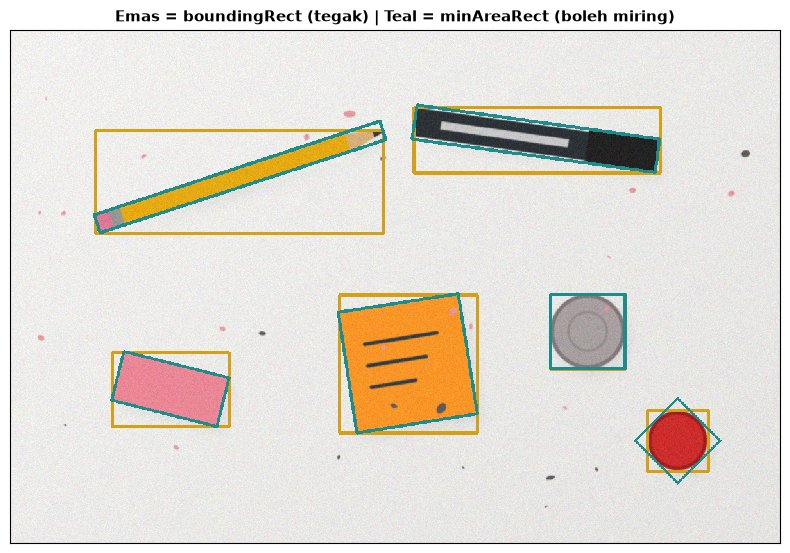

In [28]:
kontur_penuh, _ = cv2.findContours(mask_bersih, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
penghapus = min(kontur_penuh, key=lambda c: np.hypot(*(np.array(cv2.minAreaRect(c)[0]) - (250, 560))))   # objek terdekat ke (250, 560)
sederhana = cv2.approxPolyDP(penghapus, 0.02 * cv2.arcLength(penghapus, True), True)
print("Titik kontur penghapus:", len(penghapus), "-> setelah approxPolyDP:", len(sederhana))

kotak = alat.copy()
for c in objek:
    x, y, w, h = cv2.boundingRect(c)
    cv2.rectangle(kotak, (x, y), (x + w, y + h), (23, 160, 212), 3)                       # emas: tegak
    cv2.drawContours(kotak, [np.int32(cv2.boxPoints(cv2.minAreaRect(c)))], -1, (140, 140, 30), 3)  # teal: miring
jajar([(kotak, "Emas = boundingRect (tegak) | Teal = minAreaRect (boleh miring)")], ukuran=8)

---
## 8. Fitur Bentuk: Mengenali Objek dari Bentuknya

Dari setiap kontur kita hitung beberapa angka sederhana:

| Fitur | Arti | Contoh |
|---|---|---|
| **luas** | jumlah piksel di dalam kontur | sticky note paling luas |
| **keliling** | panjang garis kontur | pensil kelilingnya panjang |
| **rasio** | panjang ÷ lebar kotak miring terkecil | pensil ≫ 1, koin ≈ 1 |
| **kebulatan** | 4π × luas ÷ keliling² | lingkaran ≈ 1, persegi ≈ 0,79, garis ≈ 0 |
| **sudut** | jumlah titik setelah `approxPolyDP` | persegi panjang = 4 |

In [29]:
def fitur_bentuk(c):
    luas = cv2.contourArea(c)
    keliling = cv2.arcLength(c, True)
    (cx, cy), (rw, rh), sudut = cv2.minAreaRect(c)
    panjang, lebar = max(rw, rh), min(rw, rh)
    return {
        "luas": luas,
        "keliling": keliling,
        "rasio": panjang / max(lebar, 1e-6),
        "kebulatan": 4 * np.pi * luas / max(keliling ** 2, 1e-6),
        "sudut": len(cv2.approxPolyDP(c, 0.02 * keliling, True)),
        "pusat": (int(cx), int(cy)),
    }


def kategori(f):
    # Aturan sederhana buatan manusia (bukan machine learning)
    if f["rasio"] > 4:
        return "panjang"
    if f["kebulatan"] > 0.85:
        return "bulat"
    return "kotak"


print(f"{'no':>2} {'luas':>7} {'keliling':>8} {'rasio':>6} {'bulat':>6} {'sudut':>5}  kategori")
fitur = [fitur_bentuk(c) for c in objek]
for i, f in enumerate(fitur):
    print(f"{i + 1:>2} {f['luas']:>7.0f} {f['keliling']:>8.0f} {f['rasio']:>6.2f} {f['kebulatan']:>6.2f} {f['sudut']:>5}  {kategori(f)}")

no    luas keliling  rasio  bulat sudut  kategori
 1   12255     1039  15.62   0.14     3  panjang
 2   12942      521   2.17   0.60     4  kotak
 3   35460      787   1.00   0.72     4  kotak
 4   18057      898   7.23   0.28     4  panjang
 5   10654      385   1.00   0.90     8  bulat
 6    6882      310   1.00   0.90     8  bulat


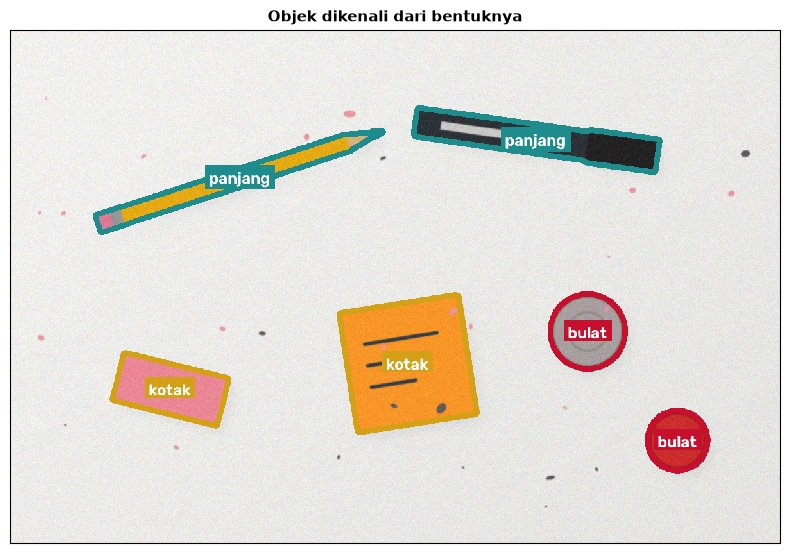

In [30]:
WARNA_KATEGORI = {"panjang": (140, 140, 30), "bulat": (46, 16, 200), "kotak": (23, 160, 212)}
akhir = alat.copy()
for c, f in zip(objek, fitur):
    k = kategori(f)
    cv2.drawContours(akhir, [c], -1, WARNA_KATEGORI[k], 7)
    label(akhir, f["pusat"], k, WARNA_KATEGORI[k], 0.85)
jajar([(akhir, "Objek dikenali dari bentuknya")], ukuran=8)

> 💡 Aturan `kategori()` ini **dibuat manusia** dari tabel fitur. Di pertemuan-pertemuan berikutnya, aturan seperti ini bisa *dipelajari* otomatis oleh model.

---
## 9. Bonus: Menemukan 4 Sudut Kertas Secara Otomatis

Di Modul 08 kita **membaca 4 sudut dokumen dengan tangan** sebelum `warpPerspective`. Sekarang kontur menemukannya sendiri:
1. Grayscale → blur → **Canny**.
2. **Dilasi** sedikit agar garis tepi kertas tersambung.
3. Ambil **kontur terbesar** → sederhanakan dengan `approxPolyDP` → kalau hasilnya **4 titik**, itulah kertasnya.
4. Urutkan sudut, lalu **luruskan** dengan `warpPerspective` (Modul 08).

Jumlah titik setelah approxPolyDP: 4
4 sudut (kiri-atas, kanan-atas, kanan-bawah, kiri-bawah): [[317, 91], [742, 149], [688, 668], [214, 590]]


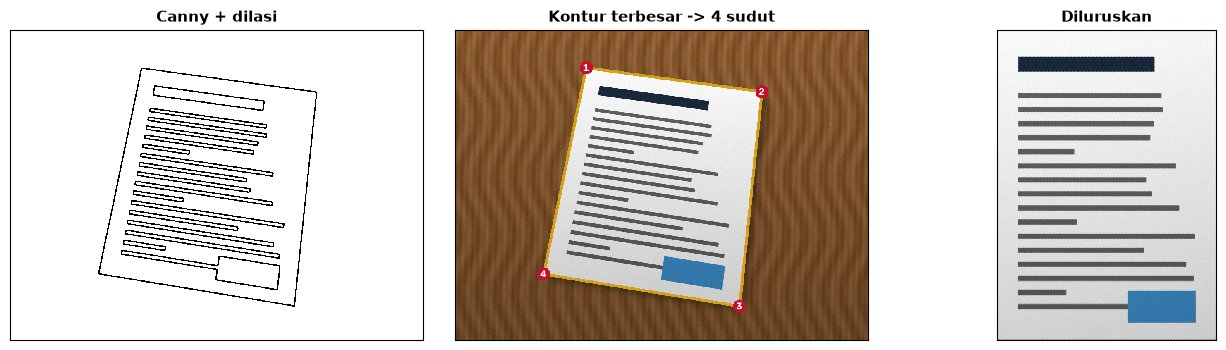

In [31]:
def urutkan_sudut(pts):
    # Urutkan 4 titik: kiri-atas, kanan-atas, kanan-bawah, kiri-bawah
    pts = pts.reshape(4, 2).astype(np.float32)
    jumlah = pts.sum(axis=1)                 # x + y: terkecil = kiri-atas, terbesar = kanan-bawah
    beda = np.diff(pts, axis=1).ravel()      # y - x: terkecil = kanan-atas, terbesar = kiri-bawah
    return np.float32([pts[np.argmin(jumlah)], pts[np.argmin(beda)], pts[np.argmax(jumlah)], pts[np.argmax(beda)]])


abu_m = cv2.cvtColor(meja, cv2.COLOR_BGR2GRAY)
tepi_m = cv2.Canny(cv2.GaussianBlur(abu_m, (5, 5), 0), 50, 150)
tepi_m = cv2.dilate(tepi_m, np.ones((3, 3), np.uint8))
kontur_m, _ = cv2.findContours(tepi_m, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
terbesar = max(kontur_m, key=cv2.contourArea)
aprx = cv2.approxPolyDP(terbesar, 0.02 * cv2.arcLength(terbesar, True), True)
print("Jumlah titik setelah approxPolyDP:", len(aprx))

if len(aprx) == 4:
    sudut4 = urutkan_sudut(aprx)
    print("4 sudut (kiri-atas, kanan-atas, kanan-bawah, kiri-bawah):", sudut4.astype(int).tolist())
    tujuan = np.float32([[0, 0], [420, 0], [420, 594], [0, 594]])    # rasio A4
    lurus = cv2.warpPerspective(meja, cv2.getPerspectiveTransform(sudut4, tujuan), (420, 594))
    tanda = meja.copy()
    cv2.drawContours(tanda, [aprx], -1, (23, 160, 212), 5)
    for i, (px, py) in enumerate(sudut4.astype(int)):
        cv2.circle(tanda, (px, py), 16, (46, 16, 200), -1)
        cv2.putText(tanda, str(i + 1), (px - 8, py + 8), cv2.FONT_HERSHEY_SIMPLEX, 0.8, (255, 255, 255), 2, cv2.LINE_AA)
    jajar([(255 - tepi_m, "Canny + dilasi"), (tanda, "Kontur terbesar -> 4 sudut"), (lurus, "Diluruskan")], ukuran=4.5)
else:
    print("Kontur terbesar bukan segi empat. Coba ubah ambang Canny atau faktor 0.02.")

### 9.1 Coba dengan Foto Anda Sendiri
1. Letakkan beberapa alat tulis di atas **kertas putih polos**, foto dari atas dengan cahaya merata (hindari bayangan tajam).
2. Simpan ke folder `image/`, isi `FOTO_SAYA`, lalu jalankan sel di bawah.
3. Kalau objek terang (misalnya penghapus putih) tidak terdeteksi, perhatikan histogramnya: apakah objek benar-benar lebih gelap dari kertas?

In [32]:
FOTO_SAYA = None     # contoh: "image/meja_saya.jpg"
MIN_LUAS_SAYA = 1500 # foto HP beresolusi besar -> remah juga lebih besar dalam piksel

if FOTO_SAYA is None:
    print("Lewati: isi FOTO_SAYA untuk mencoba foto Anda sendiri.")
else:
    img_saya = cv2.imread(FOTO_SAYA)
    if img_saya is None:
        raise FileNotFoundError(FOTO_SAYA)
    skala = 1200 / max(img_saya.shape[:2])                       # perkecil agar cepat
    img_saya = cv2.resize(img_saya, None, fx=skala, fy=skala, interpolation=cv2.INTER_AREA)
    _, T_saya, _, mask_saya = buat_mask(img_saya)
    k_saya, _ = cv2.findContours(mask_saya, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    k_saya = [c for c in k_saya if cv2.contourArea(c) >= MIN_LUAS_SAYA]
    hasil_saya = img_saya.copy()
    for i, c in enumerate(k_saya):
        f = fitur_bentuk(c)
        cv2.drawContours(hasil_saya, [c], -1, WARNA[i % len(WARNA)], 5)
        label(hasil_saya, f["pusat"], kategori(f), WARNA[i % len(WARNA)])
    print(f"Ambang Otsu = {T_saya:.0f} | objek ditemukan = {len(k_saya)}")
    jajar([(mask_saya, "Mask"), (hasil_saya, "Hasil")], ukuran=6)

Lewati: isi FOTO_SAYA untuk mencoba foto Anda sendiri.


---
## 10. Rangkuman & Kebiasaan Baik

### 📌 Ringkasan Konsep Inti Modul 09:
1. **Konvolusi**: nilai baru tiap piksel = campuran berbobot dari tetangganya; bobotnya disebut **kernel**. `cv2.filter2D` = konvolusi cepat.
2. **Box blur** merata-rata semua tetangga; **Gaussian** lebih mementingkan tetangga dekat (hasil lebih alami); **median** mengambil nilai tengah dan paling ampuh untuk **salt & pepper**.
3. Blur adalah **tawar-menawar**: σ terlalu besar ikut menghapus detail asli (PSNR turun lagi).
4. **Sharpening** = asli + k × (asli − blur). k terlalu besar → noise & halo ikut membesar.
5. **Tepi** = perubahan kecerahan mendadak. Sobel x → tepi tegak, Sobel y → tepi mendatar. **Blur dulu** sebelum mencari tepi.
6. **Canny** = blur → gradien → penipisan → dua ambang (tepi lemah disimpan jika tersambung ke tepi kuat).
7. **Threshold** (Otsu) mengubah foto menjadi **mask**; **opening** menghapus bintik, **closing** menambal lubang.
8. **Kontur** = garis keliling objek pada mask. Saring berdasarkan **luas**, lalu hitung **fitur bentuk** (rasio, kebulatan, sudut) untuk mengenali objek.

### 🧭 Lembar Contekan
| Tujuan | Kode |
|---|---|
| Konvolusi kernel bebas | `cv2.filter2D(img, -1, kernel)` |
| Box blur | `cv2.blur(img, (k, k))` |
| Gaussian blur | `cv2.GaussianBlur(img, (0, 0), sigma)` |
| Median | `cv2.medianBlur(img, 3)` |
| Sharpening | `cv2.addWeighted(img, 1 + k, cv2.GaussianBlur(img, (0, 0), s), -k, 0)` |
| Sobel | `cv2.Sobel(abu, cv2.CV_64F, 1, 0, ksize=3)` |
| Canny | `cv2.Canny(abu, 50, 150)` |
| Threshold Otsu | `cv2.threshold(abu, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)` |
| Morfologi | `cv2.morphologyEx(mask, cv2.MORPH_OPEN, kuas)` |
| Kontur | `cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)` |
| Luas & keliling | `cv2.contourArea(c)`, `cv2.arcLength(c, True)` |
| Sederhanakan | `cv2.approxPolyDP(c, 0.02 * keliling, True)` |

> 🔜 **Pertemuan berikutnya:** Video digital & motion estimation (frame, FPS, codec, optical flow).